In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
     


In [2]:
df=pd.read_csv("game.csv")

In [3]:
df.head()

,age,game_type,score,accuracy,response_time_sec,mistakes,games_played,recommended_game,recommended_level
0,78,Simple Puzzle,55.0,55.1,11.86,4,8,Word Recall,Medium
1,73,Simple Puzzle,81.5,88.4,7.20,2,20,Pattern Matching,Hard
2,64,Memory Matching,44.1,50.1,7.61,6,15,Memory Matching,Easy
3,71,Picture Recall,75.7,74.7,6.15,0,8,Pattern Matching,Hard
4,83,Picture Recall,75.8,89.6,4.94,0,22,Pattern Matching,Hard


In [4]:
df.columns.tolist()

['age',
 'game_type',
 'score',
 'accuracy',
 'response_time_sec',
 'mistakes',
 'games_played',
 'recommended_game',
 'recommended_level']

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                3000 non-null   int64  
 1   game_type          3000 non-null   object 
 2   score              3000 non-null   float64
 3   accuracy           3000 non-null   float64
 4   response_time_sec  3000 non-null   float64
 5   mistakes           3000 non-null   int64  
 6   games_played       3000 non-null   int64  
 7   recommended_game   3000 non-null   object 
 8   recommended_level  3000 non-null   object 
dtypes: float64(3), int64(3), object(3)
memory usage: 211.1+ KB


In [6]:
df.isnull().sum()

age                  0
game_type            0
score                0
accuracy             0
response_time_sec    0
mistakes             0
games_played         0
recommended_game     0
recommended_level    0
dtype: int64

In [7]:
#target 
df['recommended_level'].value_counts()

recommended_level
Medium    1453
Hard      1187
Easy       360
Name: count, dtype: int64

<Axes: xlabel='recommended_level'>

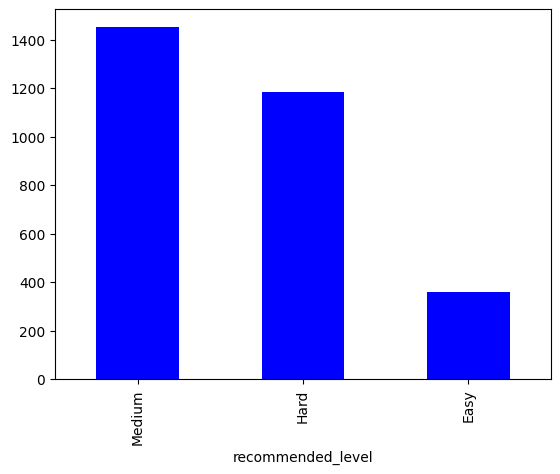

In [8]:
df['recommended_level'].value_counts().plot(kind='bar', color='blue')

In [9]:
df['recommended_game'].value_counts()

recommended_game
Pattern Matching    859
Memory Matching     530
Simple Puzzle       507
Number Sequence     473
Word Recall         316
Picture Recall      315
Name: count, dtype: int64

In [10]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

In [11]:
numerical_cols

['age', 'score', 'accuracy', 'response_time_sec', 'mistakes', 'games_played']

In [12]:
cat_cols=df.select_dtypes(include='object').columns.tolist()

In [13]:
cat_cols

['game_type', 'recommended_game', 'recommended_level']

df_columns

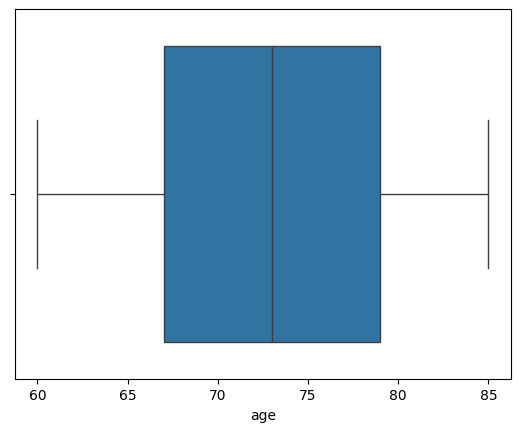

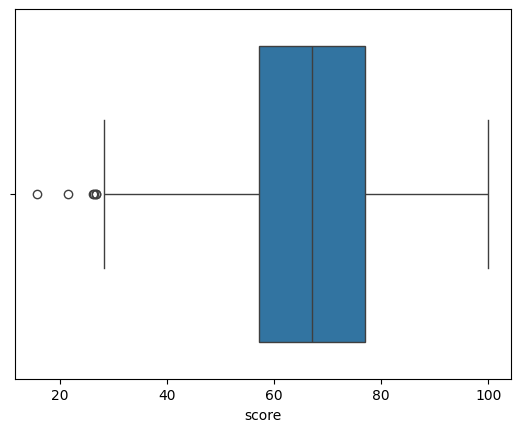

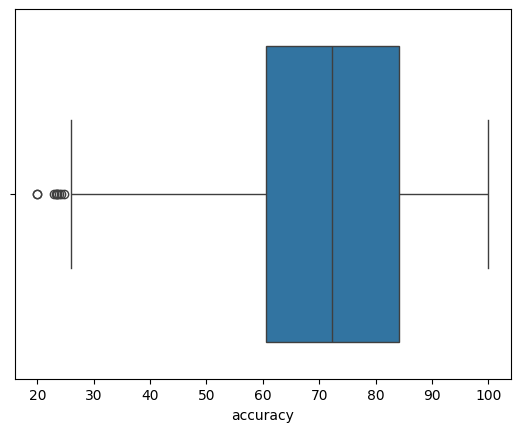

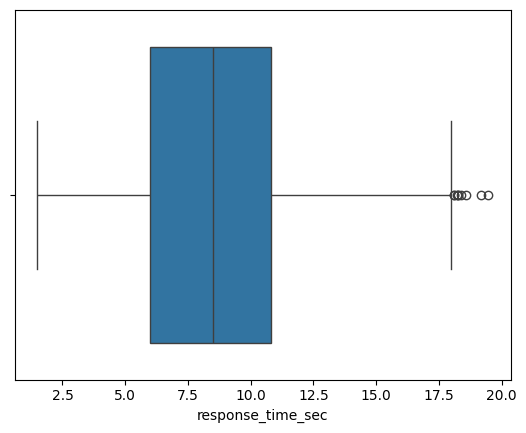

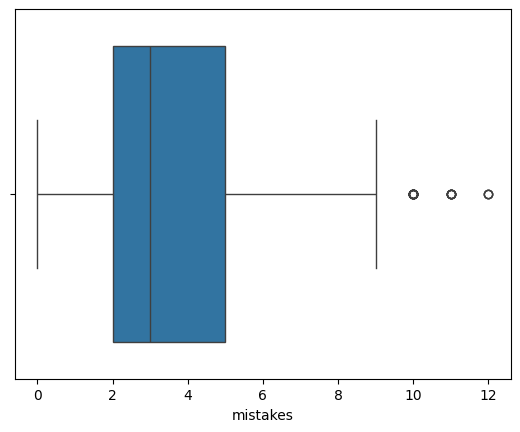

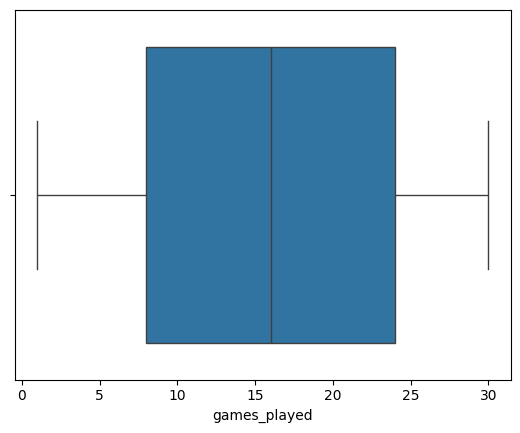

In [14]:
for i in numerical_cols:
    sns.boxplot(x=df[i])
    plt.show()

In [15]:
X=df.drop(columns=['recommended_level','recommended_game'],axis=1)
y=df[['recommended_level','recommended_game']]

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [18]:
df.iloc[:,1]


0         Simple Puzzle
1         Simple Puzzle
2       Memory Matching
3        Picture Recall
4        Picture Recall
             ...       
2995     Picture Recall
2996        Word Recall
2997    Memory Matching
2998     Picture Recall
2999      Simple Puzzle
Name: game_type, Length: 3000, dtype: object

In [19]:
df.sample(1)

,age,game_type,score,accuracy,response_time_sec,mistakes,games_played,recommended_game,recommended_level
1820,76,Memory Matching,82.8,86.3,6.65,3,17,Pattern Matching,Hard


## preproessing for logistic regession

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

In [40]:


pr_xg = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['game_type'])
    ],
    remainder='passthrough'
)

In [42]:
pr_xg

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. 

In [43]:
from sklearn.preprocessing import LabelEncoder

y_train = y_train.copy()
y_test = y_test.copy()

le_level = LabelEncoder()
le_game = LabelEncoder()

y_train['recommended_level'] = le_level.fit_transform(
    y_train['recommended_level']
)

y_train['recommended_game'] = le_game.fit_transform(
    y_train['recommended_game']
)

y_test['recommended_level'] = le_level.transform(
    y_test['recommended_level']
)

y_test['recommended_game'] = le_game.transform(
    y_test['recommended_game']
)

In [44]:
from sklearn.pipeline import Pipeline
from sklearn.multioutput import MultiOutputClassifier
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ('pr', pr_xg),
    ('classifier', MultiOutputClassifier(
        XGBClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42,
            eval_metric='logloss'
        )
    ))
])

In [45]:
xgb_pipeline.fit(X_train, y_train)

y_pred = xgb_pipeline.predict(X_test)

In [ ]:
y_pred

array([[1, 2],
       [0, 2],
       [1, 2],
       ...,
       [0, 3],
       [2, 0],
       [1, 1]], shape=(600, 2))

In [46]:
y_pred_level = le_level.inverse_transform(
    y_pred[:, 0].astype(int)
)

y_pred_game = le_game.inverse_transform(
    y_pred[:, 1].astype(int)
)

print("Recommended Level:", y_pred_level)


Recommended Level: [1 0 1 1 2 1 1 1 1 2 1 2 2 1 2 2 1 1 2 2 1 2 1 2 2 2 0 1 0 2 2 1 0 0 2 1 2
 1 1 2 2 2 2 2 2 1 2 1 2 1 2 2 1 2 2 0 2 2 0 2 1 2 1 2 0 2 2 1 2 1 1 0 0 2
 2 1 2 0 2 1 2 2 0 2 0 2 0 2 1 1 1 1 2 2 2 1 0 2 2 0 2 1 2 1 2 1 1 2 2 1 1
 1 1 2 2 2 1 2 1 0 2 1 2 0 2 1 1 0 2 2 2 0 1 2 1 1 1 2 1 2 1 1 2 1 2 2 1 2
 1 2 1 1 2 2 1 1 1 2 1 0 1 2 0 1 2 2 1 2 1 1 2 2 2 1 1 2 2 2 2 2 2 1 2 0 1
 0 2 1 1 1 2 2 2 2 0 1 2 2 1 1 1 2 2 2 2 1 1 2 1 2 0 1 0 0 2 0 1 1 1 2 1 1
 1 1 1 1 1 2 2 2 1 1 1 2 2 2 2 2 0 1 2 1 1 1 1 1 2 1 2 1 2 2 2 0 1 2 2 2 2
 1 2 1 2 1 2 1 0 2 1 2 2 2 2 0 0 0 1 1 2 0 2 2 1 2 1 1 1 0 2 1 1 2 2 2 2 0
 2 2 2 2 2 2 1 1 1 2 2 2 1 1 2 1 0 2 2 1 1 0 1 1 1 2 1 2 2 2 2 2 2 2 1 2 2
 1 1 1 1 1 0 2 1 2 2 2 1 2 2 2 1 2 2 1 2 1 2 1 0 1 1 2 2 2 1 1 1 2 1 2 1 1
 2 0 2 2 2 0 2 2 2 2 2 0 1 2 2 2 2 2 1 2 2 2 0 2 0 2 2 2 2 1 2 2 2 2 2 1 2
 2 0 1 2 0 2 1 1 2 1 1 2 2 1 1 0 2 2 1 2 1 2 2 2 1 0 2 1 1 2 0 1 2 1 2 0 0
 1 2 0 2 0 2 2 2 1 1 1 1 1 2 2 1 1 2 2 1 2 2 1 1 2 2 0 1 1 2 2 0 1 1 1 2 0
 1 1 1

In [47]:
print("Recommended Game:", y_pred_game)

Recommended Game: [2 2 2 3 0 2 1 2 2 5 2 4 4 2 3 4 2 2 3 4 2 4 2 0 4 4 3 2 0 0 3 1 3 2 4 2 4
 4 2 1 4 0 4 1 4 1 1 0 4 2 5 5 0 4 0 5 0 4 0 4 2 0 2 5 1 3 5 1 5 0 2 2 2 1
 4 2 3 4 4 2 5 0 1 4 5 0 3 0 1 2 1 2 4 0 0 1 0 1 1 5 1 2 5 0 5 2 2 4 5 2 2
 2 2 3 4 0 1 4 2 4 3 2 1 4 2 2 2 5 1 5 5 2 1 3 2 2 2 0 2 5 0 1 5 0 4 5 2 0
 5 1 1 1 0 3 2 2 2 3 0 5 2 4 1 2 0 1 2 1 2 2 1 4 1 2 0 3 1 4 4 4 0 2 3 4 1
 0 1 2 2 2 4 4 3 4 2 0 3 3 2 2 2 4 1 4 1 0 2 4 2 5 3 2 2 3 0 5 1 0 0 1 1 2
 2 2 2 0 1 2 5 4 2 1 0 4 3 0 4 4 1 2 4 2 2 2 2 0 0 0 4 2 3 4 4 3 2 4 4 5 5
 2 5 0 4 2 3 2 1 5 4 5 4 1 3 5 5 3 2 2 4 0 5 5 0 5 0 2 2 3 1 2 2 1 4 3 4 3
 0 0 0 4 4 4 2 2 0 1 0 0 3 2 5 2 5 3 5 2 2 1 0 2 2 1 2 0 4 4 0 4 4 5 2 5 5
 1 0 0 2 2 1 4 2 4 5 3 1 4 0 3 2 0 0 2 0 2 5 1 4 1 0 3 1 4 0 2 2 0 2 1 4 1
 0 3 0 5 5 0 1 0 4 4 4 3 2 0 4 3 4 1 2 1 0 3 3 3 3 4 0 5 4 2 1 5 0 0 4 1 3
 0 2 2 5 1 4 2 2 1 2 2 2 1 1 2 5 4 1 2 3 0 4 4 0 1 5 3 2 0 0 0 2 4 2 3 1 3
 2 5 1 1 5 3 4 1 2 2 0 0 2 3 0 1 2 4 0 2 4 0 2 2 3 0 0 2 1 3 5 1 2 2 2 0 4
 4 2 1 

In [50]:
import joblib

joblib.dump(le_level, "level_encoder.pkl")
joblib.dump(le_game, "game_encoder.pkl")

print("Both encoders saved successfully!")

Both encoders saved successfully!


In [51]:
import joblib

joblib.dump(xgb_pipeline, "xgb_model.pkl")
print("Model saved successfully!")

Model saved successfully!
